# Experiment 1: Find-S Algorithm

**Dataset:** Custom EnjoySport dataset; no external download required.

Run the code cell below to execute the experiment.

Training Dataset:
  Sky AirTemp Humidity   Wind Water Forecast EnjoySport
Sunny    Warm   Normal Strong  Warm     Same        Yes
Sunny    Warm     High Strong  Warm     Same        Yes
Rainy    Cold     High Strong  Warm   Change         No
Sunny    Warm     High Strong  Cool   Change        Yes
After positive example 1: ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
After positive example 2: ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
After positive example 4: ['Sunny', 'Warm', '?', 'Strong', '?', '?']
\nFinal Hypothesis:
['Sunny', 'Warm', '?', 'Strong', '?', '?']


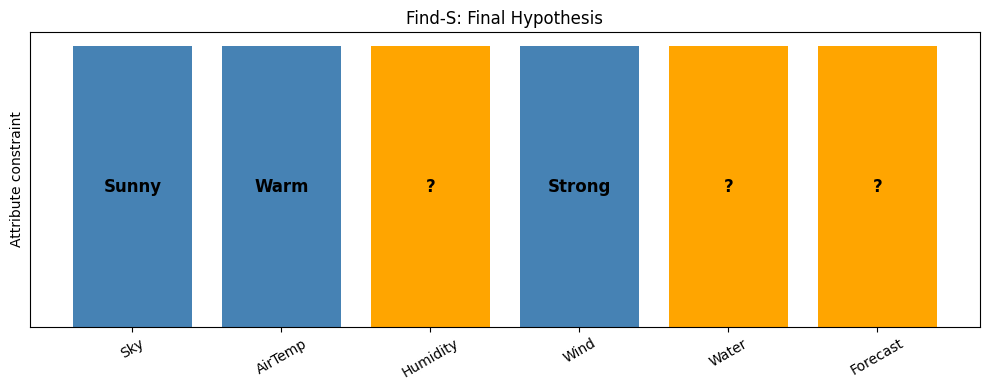

In [1]:
# Experiment 1: Find-S Algorithm
# Dataset: Custom EnjoySport dataset (no external download required)

import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Sky": ["Sunny", "Sunny", "Rainy", "Sunny"],
    "AirTemp": ["Warm", "Warm", "Cold", "Warm"],
    "Humidity": ["Normal", "High", "High", "High"],
    "Wind": ["Strong", "Strong", "Strong", "Strong"],
    "Water": ["Warm", "Warm", "Warm", "Cool"],
    "Forecast": ["Same", "Same", "Change", "Change"],
    "EnjoySport": ["Yes", "Yes", "No", "Yes"],
}
df = pd.DataFrame(data)
print("Training Dataset:")
print(df.to_string(index=False))

X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values
hypothesis = ["0"] * X.shape[1]

for i in range(len(X)):
    if y[i] == "Yes":
        for j in range(len(X[i])):
            if hypothesis[j] == "0":
                hypothesis[j] = X[i][j]
            elif hypothesis[j] != X[i][j]:
                hypothesis[j] = "?"
        print(f"After positive example {i + 1}: {hypothesis}")

print("\\nFinal Hypothesis:")
print(hypothesis)

attributes = df.columns[:-1]
colors = ["steelblue" if value != "?" else "orange" for value in hypothesis]
plt.figure(figsize=(10, 4))
plt.bar(attributes, [1] * len(attributes), color=colors)
plt.xticks(rotation=30)
plt.yticks([])
plt.title("Find-S: Final Hypothesis")
plt.ylabel("Attribute constraint")
for i, value in enumerate(hypothesis):
    plt.text(i, 0.5, value, ha="center", va="center", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()
